# EDA-EXP01 — Experimental results of SAT-Dengue

Retrospective diagnostic report, 3 November 2026. Six chapters distinguish ranking,
calibration, frozen alert policies and epidemiological composition. This reuses
consumed observations; it supplies no independent confirmation or operational approval.
G5 `NOT_APPROVED`; `champion: not_selected`.

Run from this repository with its existing `.venv` and notebook/modeling extras.
No inference, fitting, calibration, alternative threshold search or new experiment.
Inputs are explicitly identified below; absence or a changed hash stops execution.
Private row-level data and municipal tables remain under ignored `data/`.
Saved notebook outputs contain only aggregate tables and figures.

**Observed findings:** T+1's Tolima−Meta FAR gap is 13.94 percentage points (pp):
9.28 pp are attributed to prevalence in a symmetric accounting decomposition;
common-prevalence standardization leaves 4.69 pp. G0_OFF onset AUROC is
0.775–0.830 at T+1 and 0.713–0.763 at T+2: signal exists, but classes overlap.
Calibration changes sign between 2022 and 2024. DELTA lacks two mandatory P1
policies and three of six available policies lose their academic margin in
evaluation. Municipal support is thin: 273/300 T+1 and 294/298 T+2 municipality-years
have fewer than three onsets. These reused data identify several limitations,
without establishing a unique causal bottleneck or a ready successor experiment.

## 1. Integrity and comparability

The academic event is H5 onset. Academic FAR uses **target excess**, while onset
false alerts include continuations at T+2. FPR divides by negative observations;
false-alert load divides by eligible rows/12. A missing policy is never a zero alert.
Years denote target years. T+1 and T+2 are separate cohorts. Earlier experiments
are documentary context, not extra samples or directly poolable metric protocols.

### Fixed inputs and assumptions

Use every frozen benchmark key. Annual models/calibrators have different identities;
compare probability distributions within year/horizon. Descriptive bands are fixed
before computation: probability bins of 0.1; margins 0/0.05/0.15; near-P75 ±1 case.
Reliability points require at least 30 rows, five onsets and five non-onsets per bin.
Wilson 95% reference intervals describe binomial support, assuming independent
Bernoulli observations; municipal time dependence makes them illustrative, not
coverage-guaranteed inferential intervals. Four reused evaluation years cannot
support a claim of independent temporal superiority. No cluster bootstrap or count
regression is used: resampling municipalities cannot supply independent years,
and descriptive counts/exposure answer the territorial concentration question.

### Setup and strict publication reader

In [1]:
import hashlib
import importlib.metadata
import itertools
import json
import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

In [2]:
from sat_dengue.configuration import canonical_bytes
from sat_dengue.datasets.legacy_preparation.persistence import publish_bundle
from sat_dengue.datasets.stage2 import identity
from sat_dengue.training_preparation.serialization import bytes_record, serialize_table

BENCH = "data/processed/benchmark/6cfc7bcf565ebdf7ff11ab3ff79d6d91ce7d2f392958c76aa55d310ba27b6c48"
DIAG = (
    "data/processed/benchmark/diagnostico/"
    "874ef99634db44e0e71a3aba9b7195f8762ff5f9327ef0394d27ce77fc8e116c"
)
DELTA = (
    "data/processed/exp_delta01/d5c482b64e0d44e5012b20d24baa73d14f829ca4857bb2e2e53870ab3a82a284"
)
RECOVERY = (
    "data/processed/exp_delta01/recovered_selection/"
    "b2e8256c9c37f8ecdb5f895ccd6d936cfb11f3896adc654ecab3c386bf57acc1"
)
FREEZE = (
    "data/processed/exp_delta01/selection_freezes/"
    "e99f60fed004de212b4310d1114ad60e51b097a48ea7e251d2fbc41b8935d2b0"
)
KEYS = ["horizon", "municipality_code", "year_month"]
MODELS = ["R0", "G0_OFF", "G0_ON", "G1_OFF"]
YEARS = [2020, 2021, 2022, 2024]
sources = {}
tables = {}
FIGURES = ROOT / "tmp/eda-exp01/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.facecolor": "white",
    }
)
COLORS = {"Meta": "#2563a6", "Tolima": "#a25b0b", "positive": "#2563a6", "negative": "#a25b0b"}
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 14)


def verify_publication(rel, expected_sha=None):
    path = ROOT / rel
    manifest_path = path / "manifest.json"
    record = identity(manifest_path)
    if expected_sha is not None:
        assert record["sha256"] == expected_sha, rel
    manifest = json.loads(manifest_path.read_text())
    body = {k: v for k, v in manifest.items() if k != "bundle_id"}
    assert bytes_record(canonical_bytes(body))["sha256"] == path.name, rel
    assert {p.name for p in path.iterdir()} == {*manifest["files"], "manifest.json"}
    sources[str(manifest_path.relative_to(ROOT))] = record
    for name, expected in manifest["files"].items():
        assert Path(name).name == name
        file = path / name
        assert not file.is_symlink() and identity(file) == expected, str(file)
        sources[str(file.relative_to(ROOT))] = expected
    return manifest

### Verify pinned inputs and historical provenance

In [3]:
bm = verify_publication(BENCH, "4ca5b8359c914fc080c80ebf538d7d11bf1c76aa783d9434c1832d478ff15f2f")
dm = verify_publication(DELTA, "a6f67b769cc52365da097ffa1b2709452252f0b7e9a5e6a6644c70a7f1cb0a92")
diagnostic_manifest = verify_publication(DIAG)
rm = verify_publication(RECOVERY)
fm = verify_publication(FREEZE, "592a166956fdf536ea247eae6d99f3d01e6674ea8b030f2ef91ab34e7b6ddbad")
# Verify the original source records as well, without loading or invoking models.
for manifest in [bm, dm]:
    for rel, expected in manifest["sources"].items():
        assert identity(ROOT / rel) == expected, rel
        sources[rel] = expected

context_paths = [
    "docs/product/experiments/contrato.md",
    *[f"docs/product/experiments/analisis-{i}.md" for i in range(1, 8)],
    *[
        str(p.relative_to(ROOT))
        for folder in [
            "EXP02_label_stability",
            "EXP03_feature_ablation",
            "EXP03.1_add_pass_info",
            "EXP04_transporte_temporal_ de_calibracion_y_umbrales_de:decision",
            "EXP-BETA",
            "EXP-BETA01-V2",
            "benchmark",
            "EXP-DELTA01",
        ]
        for p in (ROOT / "docs/product/experiments" / folder).glob("*.md")
    ],
    "docs/product/experiments/benchmark/diagnostico/ANALYSIS.md",
    "docs/product/experiments/benchmark/diagnostico/HYPOTHESES.md",
]
for rel in context_paths:
    sources[rel] = identity(ROOT / rel)


def read_csv(rel):
    return pd.read_csv(
        ROOT / rel,
        dtype={"municipality_code": str, "department_code": str},
        float_precision="round_trip",
    )


def bool_column(series, nullable=False):
    parsed = series.astype(str).str.lower().map({"true": True, "false": False})
    assert parsed.notna().equals(series.notna())
    return parsed.astype("boolean" if nullable else bool)

### Require identical keys, outcomes and original decisions

In [4]:
d = read_csv(BENCH + "/predictions.csv")
d["alert"] = bool_column(d.alert)
delta = read_csv(DELTA + "/predictions.csv")
delta["alert"] = bool_column(delta.alert, nullable=True)
delta["available"] = bool_column(delta.available)
assert len(d) == 30450 and not d.duplicated(KEYS + ["arm"]).any()
assert len(delta) == 10150 and not delta.duplicated(KEYS + ["arm"]).any()
base = d[d.arm.eq("CHANNEL")].sort_values(KEYS).set_index(KEYS)
assert set(d.arm) == {*MODELS, "CHANNEL", "PERSISTENCE"}
assert set(d.year) == set(YEARS)
shared = ["truth", "target_excess", "target_month", "origin_count", "target_p75", "origin_zone"]
for _arm, frame in d.groupby("arm"):
    frame = frame.sort_values(KEYS).set_index(KEYS)
    assert frame.index.equals(base.index)
    pd.testing.assert_frame_equal(frame[shared], base[shared])
assert d.truth.isin([0, 1]).all() and d.target_excess.isin([0, 1]).all()
assert (d.truth <= d.target_excess).all()
for h, n, events in [(1, 2653, 313), (2, 2422, 219)]:
    assert len(base.loc[h]) == n and base.loc[h].truth.sum() == events
g0 = d[d.arm.eq("G0_OFF")].copy()
for arm in ["P0", "P1"]:
    frame = delta[delta.arm.eq(arm)].sort_values(KEYS).set_index(KEYS)
    original = g0.sort_values(KEYS).set_index(KEYS)
    pd.testing.assert_frame_equal(frame[shared + ["score"]], original[shared + ["score"]])
    if arm == "P0":
        assert np.array_equal(frame.alert.to_numpy(bool), original.alert.to_numpy(bool))
        assert np.array_equal(frame.threshold, original.threshold)
assert delta.alert.isna().equals(~delta.available)
assert (
    d[d.arm.isin(MODELS)].score.ge(d[d.arm.isin(MODELS)].threshold).to_numpy()
    == d[d.arm.isin(MODELS)].alert.to_numpy()
).all()
assert (g0[g0.horizon.eq(1)].truth == g0[g0.horizon.eq(1)].target_excess).all()

### Reconcile published denominators and metrics

In [5]:
def ratio(numerator, denominator):
    return numerator / denominator if denominator else np.nan


def describe(frame):
    n = len(frame)
    alert = frame.alert.to_numpy(bool)
    onset = frame.truth.to_numpy() == 1
    excess = frame.target_excess.to_numpy() == 1
    tp = int((alert & onset).sum())
    tp_excess = int((alert & excess).sum())
    fp = int((alert & ~excess).sum())
    fp_onset = int((alert & ~onset).sum())
    return dict(
        rows=n,
        onsets=int(onset.sum()),
        excesses=int(excess.sum()),
        alerts=int(alert.sum()),
        detected=tp,
        false_excess=fp,
        false_onset=fp_onset,
        continuation_alerts=fp_onset - fp,
        onset_prevalence=onset.mean(),
        excess_prevalence=excess.mean(),
        sensitivity=ratio(tp, onset.sum()),
        excess_sensitivity=ratio(tp_excess, excess.sum()),
        far=ratio(fp, alert.sum()),
        fpr=ratio(fp, (~excess).sum()),
        fpr_onset=ratio(fp_onset, (~onset).sum()),
        exposure=n / 12,
        false_excess_load=ratio(fp, n / 12),
        false_onset_load=ratio(fp_onset, n / 12),
    )


def group_table(frame, by):
    return pd.DataFrame(
        [
            {
                **dict(zip(by, key if isinstance(key, tuple) else (key,), strict=True)),
                **describe(part),
            }
            for key, part in frame.groupby(by, sort=True)
        ]
    )


published = pd.read_csv(ROOT / BENCH / "metrics.csv", dtype={"year": str, "department": str})
for row in published.itertuples(index=False):
    part = d[d.horizon.eq(row.horizon) & d.arm.eq(row.arm)]
    if row.year != "all":
        part = part[part.year.eq(int(row.year))]
    if row.department != "all":
        part = part[part.department_code.eq(row.department)]
    actual = describe(part)
    for ours, theirs in [
        ("rows", "rows"),
        ("onsets", "onsets"),
        ("detected", "detected"),
        ("alerts", "alerts"),
        ("false_excess", "false_alerts_excess"),
        ("false_onset", "false_alerts"),
        ("far", "far_excess"),
        ("fpr", "fpr_excess"),
        ("sensitivity", "sensitivity"),
    ]:
        assert np.isclose(actual[ours], getattr(row, theirs), equal_nan=True), (row.arm, ours)
    if row.arm in MODELS:
        assert np.isclose(average_precision_score(part.truth, part.score), row.average_precision)
        assert np.isclose(brier_score_loss(part.truth, part.score), row.brier)
for private, public in [
    ("metrics.csv", "METRICS_BY_STRATUM.csv"),
    ("comparisons.csv", "PAIRED_COMPARISONS.csv"),
]:
    assert (ROOT / BENCH / private).read_bytes() == (
        ROOT / "docs/product/experiments/benchmark" / public
    ).read_bytes()
coverage = group_table(g0, ["horizon", "year", "department_code"])
coverage["municipalities"] = (
    g0.groupby(["horizon", "year", "department_code"]).municipality_code.nunique().to_numpy()
)
tables["coverage"] = coverage
display(
    coverage[["horizon", "year", "department_code", "rows", "municipalities", "onsets", "excesses"]]
)
print("PASS: all 180 benchmark strata, exact six-arm cohorts, P0/P1 keys and P0 decisions.")

,horizon,year,department_code,rows,municipalities,onsets,excesses
0,1,2020,50,281,29,26,26
1,1,2020,73,380,47,43,43
2,1,2021,50,318,29,24,24
3,1,2021,73,528,47,28,28
4,1,2022,50,210,29,49,49
5,1,2022,73,483,47,40,40
6,1,2024,50,215,29,47,47
7,1,2024,73,238,43,56,56
8,2,2020,50,254,29,17,24
9,2,2020,73,334,47,34,48


PASS: all 180 benchmark strata, exact six-arm cohorts, P0/P1 keys and P0 decisions.


## 2. Distribution of false alerts

For **excess** prevalence π, excess sensitivity s and excess FPR f:
`FAR = f(1−π) / [sπ + f(1−π)]`.
T+2 onset sensitivity is deliberately excluded from this identity. Standardization
substitutes each horizon's pooled excess prevalence while retaining each department's
observed s/f; it is an accounting scenario, not a realizable policy or causal effect.
The three-factor Shapley decomposition averages the six possible substitution orders
from Meta to Tolima; contributions sum exactly to the observed FAR gap.

,horizon,arm,department_code,rows,onsets,excesses,alerts,...,excess_sensitivity,far,fpr,fpr_onset,exposure,false_excess_load,false_onset_load
2,1,G0_OFF,50,1024,146,146,140,...,0.5068,0.4714,0.0752,0.0752,85.3333,0.7734,0.7734
3,1,G0_OFF,73,1629,167,167,185,...,0.4311,0.6108,0.0773,0.0773,135.7500,0.8324,0.8324
14,2,G0_OFF,50,943,96,154,91,...,0.2532,0.5714,0.0659,0.0803,78.5833,0.6617,0.8653
15,2,G0_OFF,73,1479,123,194,132,...,0.2784,0.5909,0.0607,0.0686,123.2500,0.6329,0.7546


,horizon,arm,observed_gap_pp,prevalence_pp,sensitivity_pp,fpr_pp,reference_prevalence,standardized_Meta_far,standardized_Tolima_far,standardized_gap_pp
1,1,G0_OFF,13.9382,9.2785,3.9778,0.6819,0.1180,0.5258,0.5727,4.6905
6,2,G0_OFF,1.9481,6.2363,-2.2925,-1.9958,0.1437,0.6080,0.5652,-4.2844


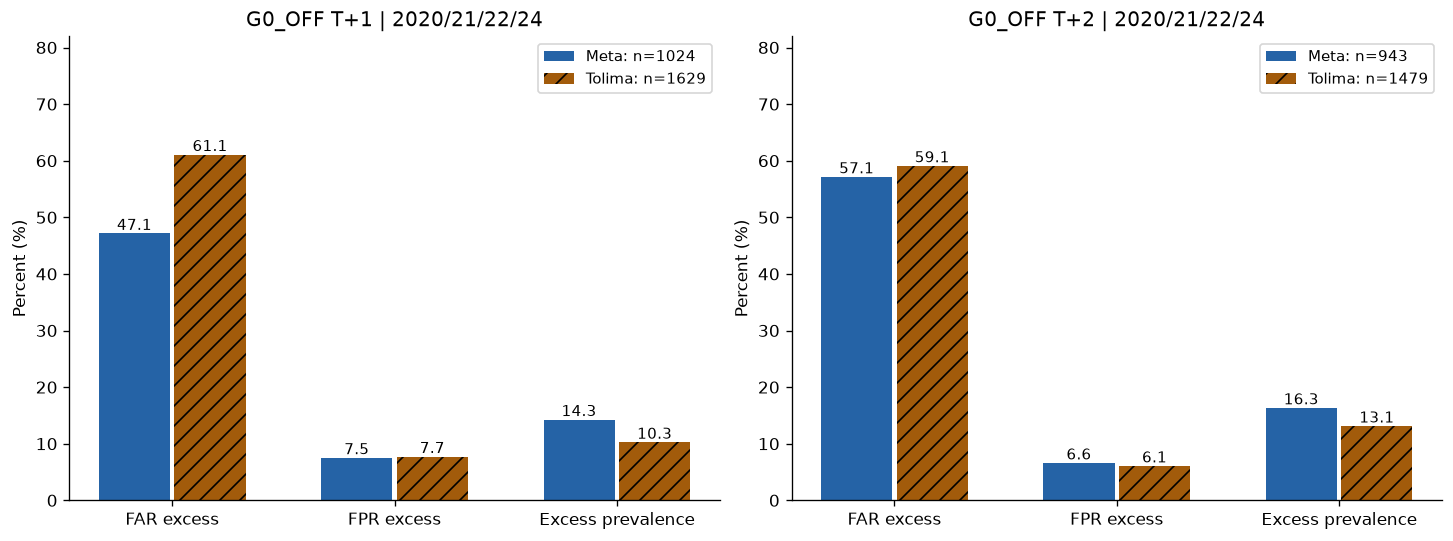

In [6]:
department = group_table(d, ["horizon", "arm", "department_code"])
annual_department = group_table(d, ["horizon", "year", "arm", "department_code"])


def far_identity(prevalence, sensitivity, fpr):
    return ratio(fpr * (1 - prevalence), sensitivity * prevalence + fpr * (1 - prevalence))


decomposition = []
for (h, arm), frame in department.groupby(["horizon", "arm"]):
    if arm == "PERSISTENCE":
        continue
    indexed = frame.set_index("department_code")
    a, b = indexed.loc["50"], indexed.loc["73"]
    factors = ["excess_prevalence", "excess_sensitivity", "fpr"]
    for row in [a, b]:
        assert np.isclose(far_identity(*[row[k] for k in factors]), row.far)
    contributions = dict.fromkeys(factors, 0.0)
    for order in itertools.permutations(factors):
        current = {k: a[k] for k in factors}
        for factor in order:
            before = far_identity(*[current[k] for k in factors])
            current[factor] = b[factor]
            contributions[factor] += (far_identity(*[current[k] for k in factors]) - before) / 6
    prevalence = g0[g0.horizon.eq(h)].target_excess.mean()
    standardized_a = far_identity(prevalence, a.excess_sensitivity, a.fpr)
    standardized_b = far_identity(prevalence, b.excess_sensitivity, b.fpr)
    gap = b.far - a.far
    assert np.isclose(sum(contributions.values()), gap)
    decomposition.append(
        dict(
            horizon=h,
            arm=arm,
            observed_gap_pp=100 * gap,
            prevalence_pp=100 * contributions["excess_prevalence"],
            sensitivity_pp=100 * contributions["excess_sensitivity"],
            fpr_pp=100 * contributions["fpr"],
            reference_prevalence=prevalence,
            standardized_Meta_far=standardized_a,
            standardized_Tolima_far=standardized_b,
            standardized_gap_pp=100 * (standardized_b - standardized_a),
        )
    )
decomposition = pd.DataFrame(decomposition)
tables.update(
    department=department, annual_department=annual_department, decomposition=decomposition
)
display(department[department.arm.eq("G0_OFF")].round(4))
display(decomposition[decomposition.arm.eq("G0_OFF")].round(4))


def finish(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    display(Image(data=(FIGURES / f"{name}.png").read_bytes()))
    plt.close(fig)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
for h, ax in zip([1, 2], axes, strict=True):
    part = department[(department.arm == "G0_OFF") & (department.horizon == h)].set_index(
        "department_code"
    )
    for i, (dep, label) in enumerate([("50", "Meta"), ("73", "Tolima")]):
        row = part.loc[dep]
        values = 100 * row[["far", "fpr", "excess_prevalence"]].to_numpy(float)
        bars = ax.bar(
            np.arange(3) + i * 0.34,
            values,
            width=0.32,
            label=f"{label}: n={int(row.rows)}",
            color=COLORS[label],
            hatch=["", "//"][i],
        )
        ax.bar_label(bars, fmt="%.1f", fontsize=9)
    ax.set(
        xticks=np.arange(3) + 0.17,
        xticklabels=["FAR excess", "FPR excess", "Excess prevalence"],
        ylabel="Percent (%)",
        ylim=(0, 82),
        title=f"G0_OFF T+{h} | 2020/21/22/24",
    )
    ax.legend(fontsize=9)
finish(fig, "01_department_rates")

At T+1, G0_OFF FPRs are 7.52%/7.73% in Meta/Tolima, but FARs are 47.14%/61.08%. The 13.94 pp gap decomposes into prevalence +9.28, excess sensitivity +3.98 and FPR +0.68 pp. At common prevalence the gap is +4.69 pp. At T+2, the observed +1.95 pp gap reverses to −4.28 pp at common excess prevalence; onset and excess targets must remain separate.

## 3. Probability separability

AP and AUROC concern **onset**, whereas FAR concerns excess. AP depends on
prevalence; `AP/prevalence` is descriptive context, not a corrected causal ranking.
Each panel below is one annual G0_OFF procedure. Histograms show fractions within
TP/FP/FN/TN onset classes, with their denominators; annual probability scales are
never pooled for ranking or score-distribution interpretation. Only the saved
threshold is drawn. Quantiles and signed distances to that threshold are retained
for every model/year/horizon/outcome in the private publication.

,horizon,year,arm,rows,onsets,prevalence,AP,...,mean_score,calibration_gap,AP_over_prevalence,threshold,score_q25,score_median,score_q75
0,1,2020,G0_OFF,661,69,0.1044,0.3423,...,0.1104,0.0060,3.2789,0.1852,0.0599,0.0923,0.1356
4,1,2021,G0_OFF,846,52,0.0615,0.1995,...,0.1071,0.0457,3.2452,0.2504,0.0523,0.0992,0.1300
8,1,2022,G0_OFF,693,89,0.1284,0.4546,...,0.2404,0.1119,3.5398,0.3574,0.1540,0.2276,0.2989
12,1,2024,G0_OFF,453,103,0.2274,0.5251,...,0.1048,-0.1226,2.3095,0.1500,0.0613,0.0835,0.1281
16,2,2020,G0_OFF,588,51,0.0867,0.2770,...,0.0724,-0.0143,3.1938,0.1146,0.0478,0.0643,0.0903
20,2,2021,G0_OFF,779,45,0.0578,0.2265,...,0.0872,0.0294,3.9202,0.2008,0.0500,0.0807,0.1097
24,2,2022,G0_OFF,641,62,0.0967,0.2110,...,0.1748,0.0781,2.1814,0.2620,0.1158,0.1713,0.2164
28,2,2024,G0_OFF,414,61,0.1473,0.3607,...,0.0721,-0.0753,2.4481,0.1060,0.0473,0.0635,0.0832


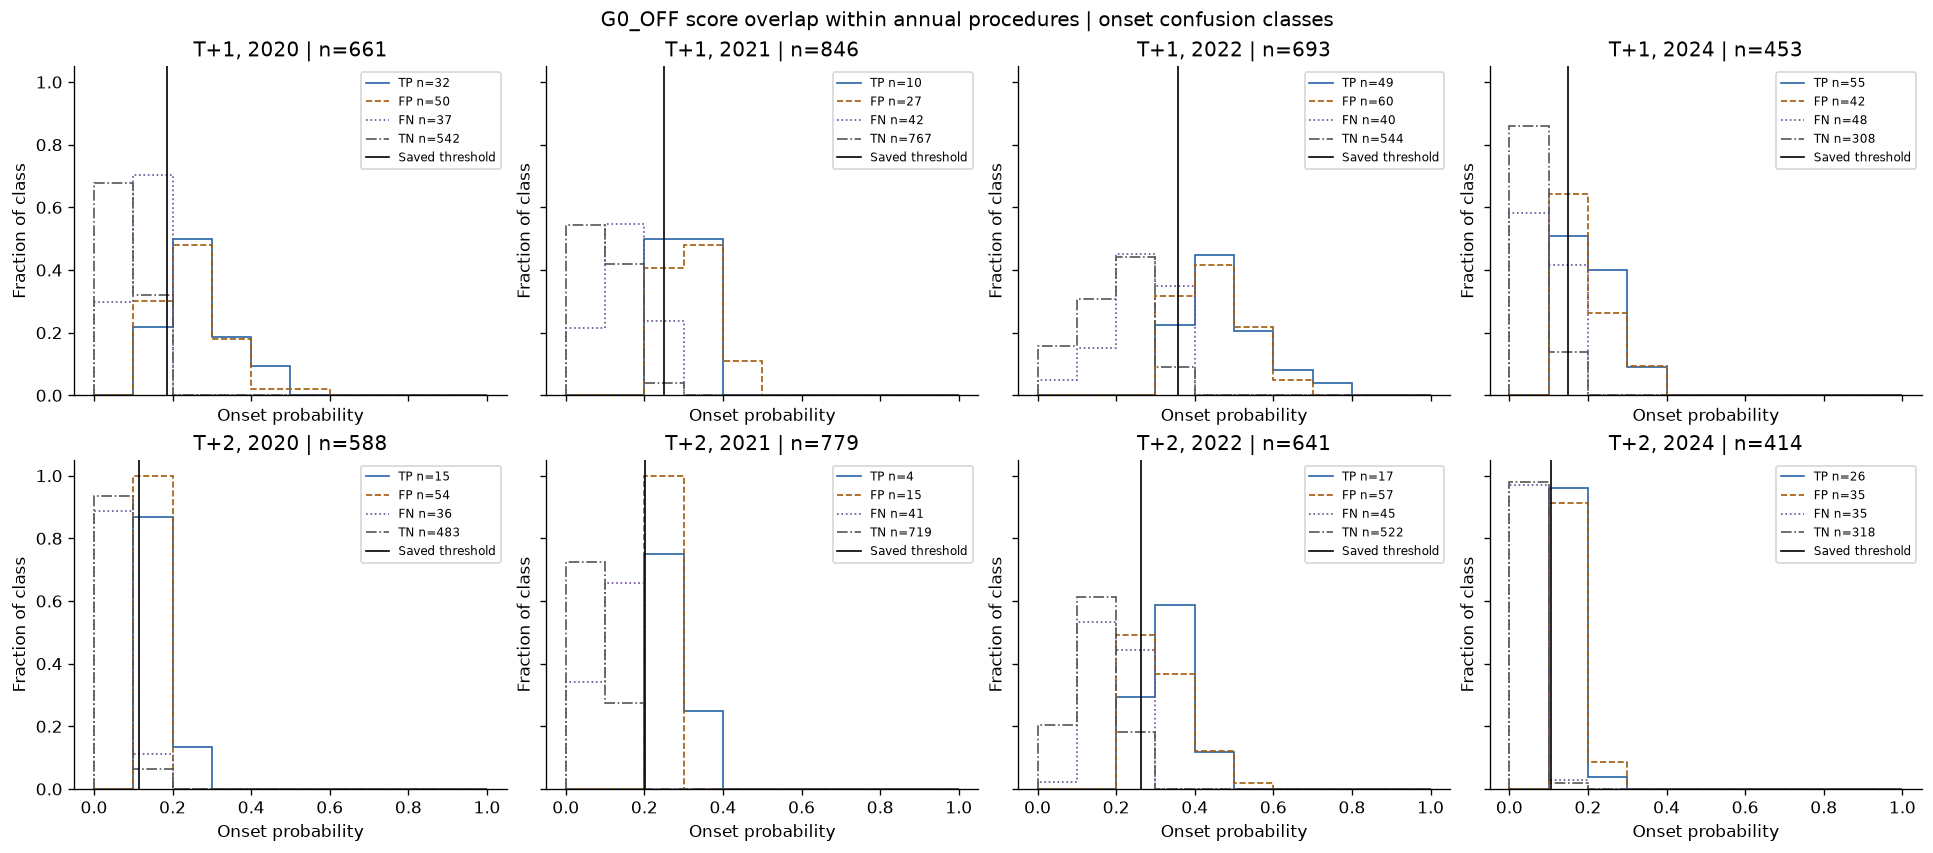

In [7]:
discrimination = []
quantiles = []
real_class = []
score_ecdf = []
reliability = []
for (h, year, arm), part in d[d.arm.isin(MODELS)].groupby(["horizon", "year", "arm"]):
    assert part.model_identity.nunique() == 1 and part.threshold.nunique() == 1
    prevalence = part.truth.mean()
    discrimination.append(
        dict(
            horizon=h,
            year=year,
            arm=arm,
            rows=len(part),
            onsets=int(part.truth.sum()),
            prevalence=prevalence,
            AP=average_precision_score(part.truth, part.score),
            AUROC=roc_auc_score(part.truth, part.score),
            brier=brier_score_loss(part.truth, part.score),
            mean_score=part.score.mean(),
            calibration_gap=part.score.mean() - prevalence,
            AP_over_prevalence=average_precision_score(part.truth, part.score) / prevalence,
            threshold=part.threshold.iloc[0],
            score_q25=part.score.quantile(0.25),
            score_median=part.score.median(),
            score_q75=part.score.quantile(0.75),
        )
    )
    for truth, sub in part.groupby("truth"):
        real_class.append(
            dict(
                horizon=h,
                year=year,
                arm=arm,
                truth=truth,
                rows=len(sub),
                q10=sub.score.quantile(0.1),
                q25=sub.score.quantile(0.25),
                median=sub.score.median(),
                q75=sub.score.quantile(0.75),
                q90=sub.score.quantile(0.9),
            )
        )
        for point in np.linspace(0, 1, 11):
            score_ecdf.append(
                dict(
                    horizon=h,
                    year=year,
                    arm=arm,
                    truth=truth,
                    score_point=point,
                    rows=len(sub),
                    ecdf=sub.score.le(point).mean(),
                )
            )
    for outcome, sub in part.groupby("onset_class"):
        margins = sub.score - sub.threshold
        quantiles.append(
            dict(
                horizon=h,
                year=year,
                arm=arm,
                outcome=outcome,
                rows=len(sub),
                score_q10=sub.score.quantile(0.1),
                score_median=sub.score.median(),
                score_q90=sub.score.quantile(0.9),
                margin_q10=margins.quantile(0.1),
                margin_median=margins.median(),
                margin_q90=margins.quantile(0.9),
                within_005=int(margins.abs().le(0.05).sum()),
                above_005_to_015=int((margins.gt(0.05) & margins.le(0.15)).sum()),
                above_015=int(margins.gt(0.15).sum()),
            )
        )
    bins = pd.cut(part.score, np.linspace(0, 1, 11), include_lowest=True)
    for band, sub in part.groupby(bins, observed=True):
        events = int(sub.truth.sum())
        reliability.append(
            dict(
                horizon=h,
                year=year,
                arm=arm,
                bin=str(band),
                rows=len(sub),
                onsets=events,
                mean_score=sub.score.mean(),
                observed=sub.truth.mean(),
                supported=len(sub) >= 30 and events >= 5 and len(sub) - events >= 5,
            )
        )
discrimination = pd.DataFrame(discrimination)
tables.update(
    discrimination=discrimination,
    score_quantiles=pd.DataFrame(quantiles),
    real_class_quantiles=pd.DataFrame(real_class),
    score_ecdf=pd.DataFrame(score_ecdf),
    reliability=pd.DataFrame(reliability),
)
display(discrimination[discrimination.arm.eq("G0_OFF")].round(4))

fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout="constrained", sharex=True, sharey=True)
styles = {
    "TP": ("#2563a6", "-"),
    "FP": ("#a25b0b", "--"),
    "FN": ("#6b4c9a", ":"),
    "TN": ("#555555", "-."),
}
for h, row_axes in zip([1, 2], axes, strict=True):
    for year, ax in zip(YEARS, row_axes, strict=True):
        part = g0[(g0.horizon == h) & (g0.year == year)]
        for outcome, (color, style) in styles.items():
            sub = part[part.onset_class.eq(outcome)]
            values, edges = np.histogram(sub.score, bins=np.linspace(0, 1, 11))
            if len(sub):
                ax.stairs(
                    values / len(sub),
                    edges,
                    label=f"{outcome} n={len(sub)}",
                    color=color,
                    linestyle=style,
                )
        ax.axvline(part.threshold.iloc[0], color="black", linewidth=1, label="Saved threshold")
        ax.set(
            title=f"T+{h}, {year} | n={len(part)}",
            xlabel="Onset probability",
            ylabel="Fraction of class",
        )
        ax.legend(fontsize=7)
fig.suptitle("G0_OFF score overlap within annual procedures | onset confusion classes")
finish(fig, "02_probability_distributions")

True and false alerts occupy overlapping score bins in every annual procedure. G0_OFF AUROC exceeds 0.5 in all eight cells, yet T+2/2022 reaches only 0.713 (AP 0.211 versus onset prevalence 0.0967). This supports limited separability, without establishing that discrimination alone causes failure of the academic rule. The other models and real-class quantiles/ECDFs remain in the derived tables.

### Paired errors and detections

All four model decisions share identical municipality-origin keys within a horizon.
We count each opportunity once for the multiplicity table. Shared errors are not
independent replications; exclusive errors are defined against the other three models.
CHANNEL comparisons use the same observations; successful G0-only detections are
retained alongside its extra false alerts.

In [8]:
multiplicity = []
exclusive = []
overlap = []
for (h, year), part in d.groupby(["horizon", "year"]):
    matrix = part.pivot(index=KEYS, columns="arm", values="alert")
    labels = part[part.arm.eq("CHANNEL")].set_index(KEYS).reindex(matrix.index)
    votes = matrix[MODELS].sum(axis=1)
    for outcome, mask in [
        ("non_excess", labels.target_excess.eq(0)),
        ("onset", labels.truth.eq(1)),
    ]:
        for k in range(5):
            multiplicity.append(
                dict(
                    horizon=h,
                    year=year,
                    outcome=outcome,
                    models_alerting=k,
                    rows=int((mask & votes.eq(k)).sum()),
                    opportunities=int(mask.sum()),
                )
            )
    for arm in MODELS:
        only = matrix[arm] & matrix[[a for a in MODELS if a != arm]].sum(axis=1).eq(0)
        exclusive.append(
            dict(
                horizon=h,
                year=year,
                arm=arm,
                exclusive_false_excess=int((only & labels.target_excess.eq(0)).sum()),
                exclusive_detected=int((only & labels.truth.eq(1)).sum()),
            )
        )
    for a, b in itertools.combinations([*MODELS, "CHANNEL"], 2):
        for outcome, mask in [
            ("false_excess", labels.target_excess.eq(0)),
            ("detected", labels.truth.eq(1)),
        ]:
            overlap.append(
                dict(
                    horizon=h,
                    year=year,
                    a=a,
                    b=b,
                    outcome=outcome,
                    both=int((mask & matrix[a] & matrix[b]).sum()),
                    a_only=int((mask & matrix[a] & ~matrix[b]).sum()),
                    b_only=int((mask & ~matrix[a] & matrix[b]).sum()),
                    neither=int((mask & ~matrix[a] & ~matrix[b]).sum()),
                )
            )
tables.update(
    multiplicity=pd.DataFrame(multiplicity),
    exclusive=pd.DataFrame(exclusive),
    overlap=pd.DataFrame(overlap),
)
diagnostic = json.loads((ROOT / DIAG / "tables.json").read_text())
expected_shared = pd.DataFrame(diagnostic["shared_errors"])
expected_shared = expected_shared[expected_shared.outcome.isin(["non_excess", "onset"])].rename(
    columns={"number_models_alerting": "models_alerting"}
)
cols = ["horizon", "year", "outcome", "models_alerting", "rows", "opportunities"]
order = cols[:4]
pd.testing.assert_frame_equal(
    tables["multiplicity"][cols].sort_values(order).reset_index(drop=True),
    expected_shared[cols].sort_values(order).reset_index(drop=True),
)
display(
    tables["overlap"]
    .query("a == 'G0_OFF' and b == 'CHANNEL'")
    .groupby(["horizon", "outcome"])[["both", "a_only", "b_only", "neither"]]
    .sum()
)

both  a_only  b_only  neither
horizon outcome                                    
1       detected        75      71      19      148
        false_excess    61     118      24     2137
2       detected        29      33      17      140
        false_excess    38      92      76     1868

## 4. Calibration and temporal stability

Mean predicted minus observed onset frequency measures calibration in the large.
Brier combines calibration and discrimination; it does not isolate either component.
Reliability uses fixed bins and the support rule in Chapter 1; unsupported bins
remain in the private table but no reliable curve is claimed there. Annual
procedures were separately trained/calibrated: changes mix composition and procedure
changes, and cannot be attributed to drift of a single fixed model.

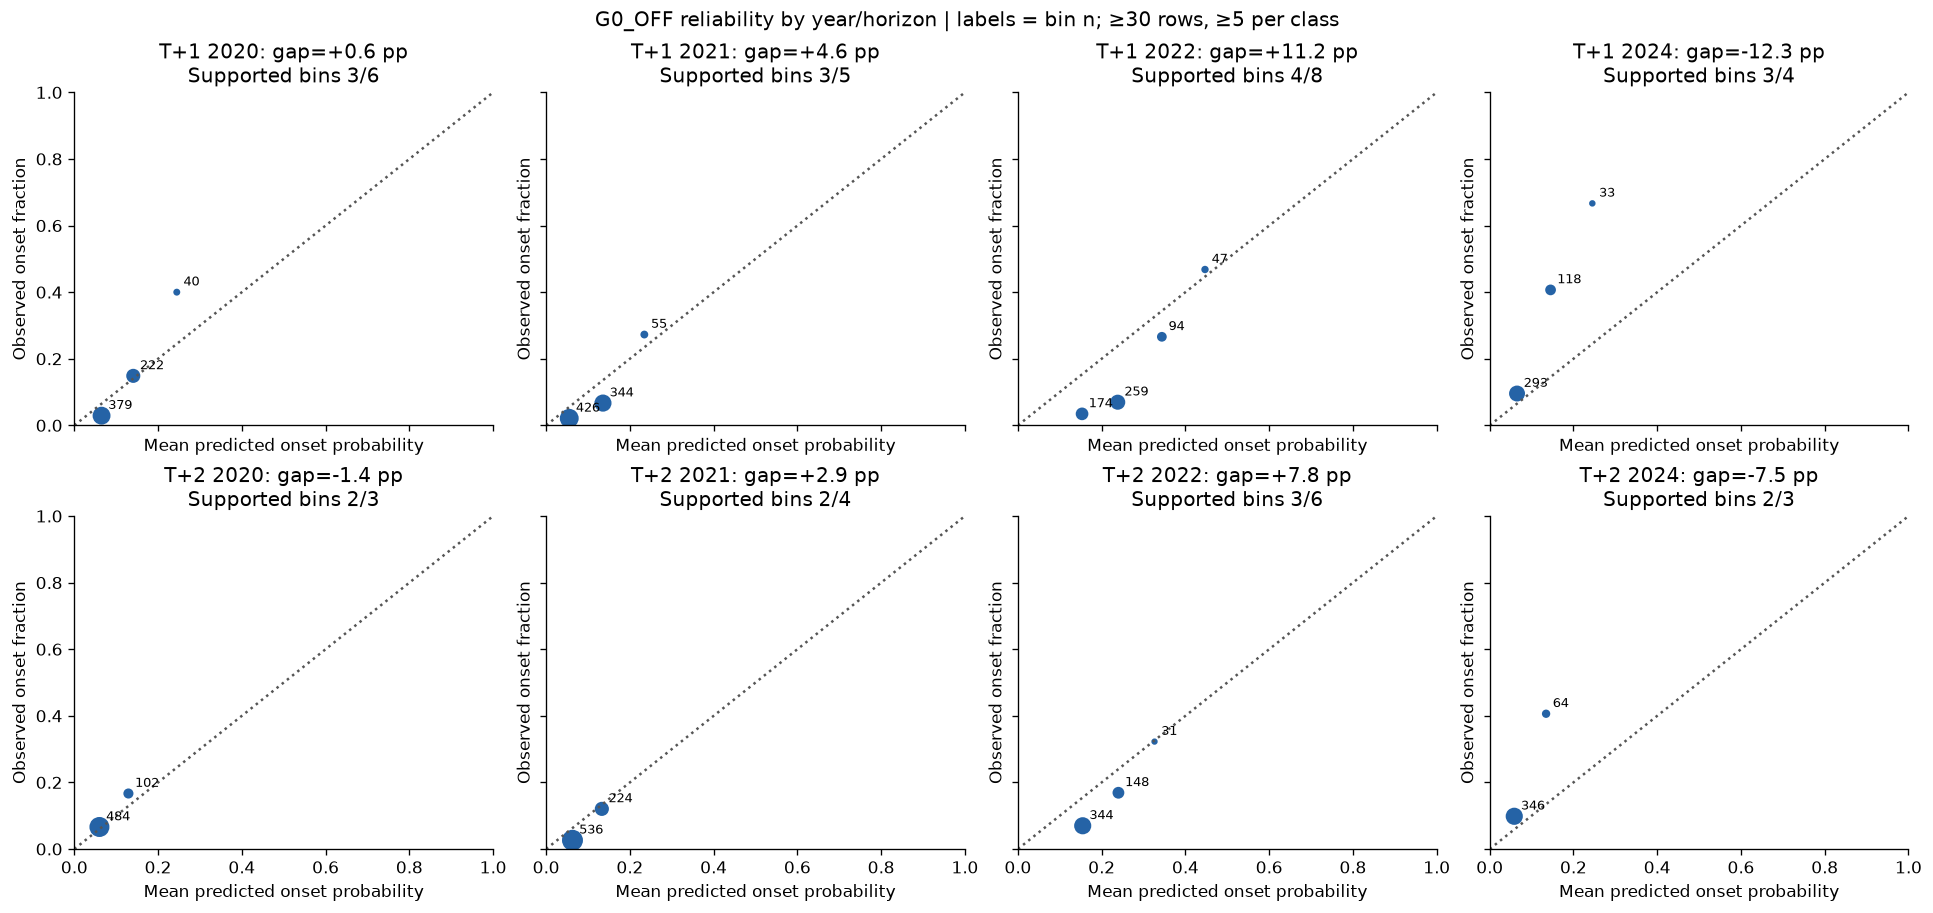

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), layout="constrained", sharex=True, sharey=True)
for h, row_axes in zip([1, 2], axes, strict=True):
    for year, ax in zip(YEARS, row_axes, strict=True):
        rel = tables["reliability"].query("arm == 'G0_OFF' and horizon == @h and year == @year")
        supported = rel[rel.supported]
        ax.plot([0, 1], [0, 1], ":", color="#555555")
        ax.scatter(
            supported.mean_score,
            supported.observed,
            s=supported.rows / 4,
            color="#2563a6",
            marker="o",
        )
        for row in supported.itertuples():
            ax.annotate(
                str(row.rows),
                (row.mean_score, row.observed),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=8,
            )
        metric = discrimination.query("arm == 'G0_OFF' and horizon == @h and year == @year").iloc[0]
        ax.set(
            title=(
                f"T+{h} {year}: gap={100 * metric.calibration_gap:+.1f} pp\n"
                f"Supported bins {len(supported)}/{len(rel)}"
            ),
            xlabel="Mean predicted onset probability",
            ylabel="Observed onset fraction",
            xlim=(0, 1),
            ylim=(0, 1),
        )
fig.suptitle("G0_OFF reliability by year/horizon | labels = bin n; ≥30 rows, ≥5 per class")
finish(fig, "03_reliability")

G0_OFF calibration-in-the-large gaps are +11.19/+7.81 pp in 2022 and −12.26/−7.53 pp in 2024 (T+1/T+2). T+1/2022 AUROC is 0.830, above the other years, despite all four models failing the annual academic FAR margin. Ranking, prevalence, calibration and a relative decision constraint describe different properties.

### DELTA selection versus evaluation, without new policy selection

Read the already published policies/frontier and recovered selection probabilities.
The following calculations describe probability quality in the historical selection
block and its corresponding evaluation block. They do not compare identical observations
across time or authenticate absent original selection arrays. Evaluation copies are
paired exactly with benchmark G0_OFF. Missing P1 policies stay unavailable in every
complete-horizon comparison. No candidate thresholds are recalculated.

,horizon,year,stage,rows,onsets,prevalence,mean_score,calibration_gap,AP,AUROC,brier
0,1,2020,selection,376,118,0.3138,0.1356,-0.1782,0.5133,0.7138,0.2292
1,1,2020,evaluation,661,69,0.1044,0.1104,0.0060,0.3423,0.8126,0.0823
2,1,2021,selection,661,69,0.1044,0.1425,0.0381,0.3400,0.8147,0.0822
3,1,2021,evaluation,846,52,0.0615,0.1071,0.0457,0.1995,0.7754,0.0558
4,1,2022,selection,846,52,0.0615,0.2052,0.1437,0.1862,0.7630,0.0778
5,1,2022,evaluation,693,89,0.1284,0.2404,0.1119,0.4546,0.8301,0.1038
6,1,2024,selection,410,125,0.3049,0.1050,-0.1998,0.5278,0.7401,0.2349
7,1,2024,evaluation,453,103,0.2274,0.1048,-0.1226,0.5251,0.7996,0.1695
8,2,2020,selection,355,73,0.2056,0.0787,-0.1269,0.3344,0.6325,0.1743
9,2,2020,evaluation,588,51,0.0867,0.0724,-0.0143,0.2770,0.7562,0.0750


,horizon,year,status,threshold,development_channel_far,development_P1_far,evaluation_P1_far,evaluation_channel_far,evaluation_condition_C
0,1,2020,EVALUABLE,0.2586,0.3333,0.3611,0.6061,0.5814,True
1,1,2021,EVALUABLE,0.2746,0.5814,0.6167,0.7037,0.5455,False
2,1,2022,NO_EVALUABLE,NaN,0.5455,NaN,NaN,0.4419,NaN
3,1,2024,EVALUABLE,0.2034,0.3519,0.4000,0.3415,0.4085,True
4,2,2020,EVALUABLE,0.1146,0.3448,0.3333,0.7101,0.6364,False
5,2,2021,EVALUABLE,0.1448,0.6364,0.6855,0.7407,0.7308,True
6,2,2022,EVALUABLE,0.2473,0.7308,0.7767,0.6277,0.5000,False
7,2,2024,NO_EVALUABLE,NaN,0.2549,NaN,NaN,0.4699,NaN


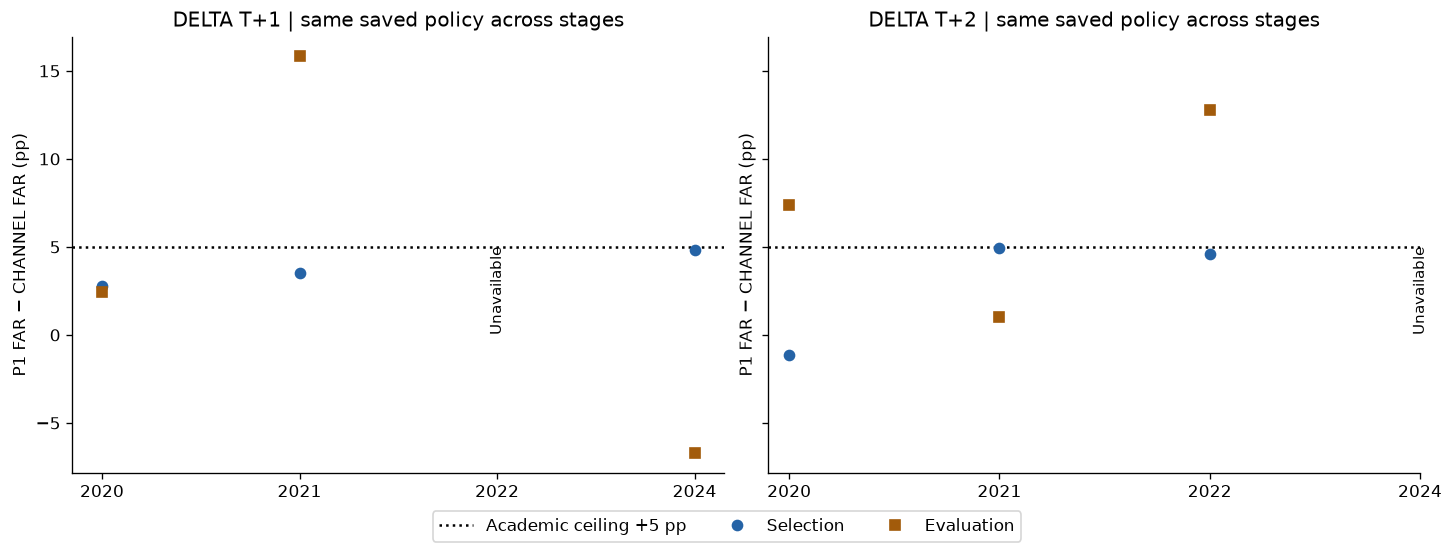

In [10]:
transport = pd.read_csv(ROOT / DELTA / "transport.csv")
frontier = pd.read_csv(ROOT / DELTA / "selection_frontier.csv")
delta_metrics = pd.read_csv(ROOT / DELTA / "metrics.csv", dtype={"year": str, "department": str})
selection_comparison = []
feasibility = []
for h in [1, 2]:
    for year in YEARS:
        selection = read_csv(RECOVERY + f"/selection-h{h}-{year}.csv")
        evaluation = g0[(g0.horizon == h) & (g0.year == year)]
        assert selection.role.eq("selection").all()
        assert set(selection.target_month.str[:4].astype(int)) == {year - 1}
        assert selection.target_month.max() < evaluation.target_month.min()
        for stage, part, truth in [
            ("selection", selection, selection.onset_target),
            ("evaluation", evaluation, evaluation.truth),
        ]:
            selection_comparison.append(
                dict(
                    horizon=h,
                    year=year,
                    stage=stage,
                    rows=len(part),
                    onsets=int(truth.sum()),
                    prevalence=truth.mean(),
                    mean_score=part.score.mean(),
                    calibration_gap=part.score.mean() - truth.mean(),
                    AP=average_precision_score(truth, part.score),
                    AUROC=roc_auc_score(truth, part.score),
                    brier=brier_score_loss(truth, part.score),
                )
            )
        saved = frontier[(frontier.horizon == h) & (frontier.year == year)]
        feasibility.append(
            dict(
                horizon=h,
                year=year,
                saved_thresholds=int(saved.threshold.notna().sum()),
                saved_feasible=int(saved.feasible.sum()),
            )
        )
# Independently reconcile every DELTA metric stratum and retain null decisions.
for row in delta_metrics.itertuples(index=False):
    part = delta[(delta.horizon == row.horizon) & (delta.arm == row.arm)]
    if row.year != "all":
        part = part[part.year.eq(int(row.year))]
    if row.department != "all":
        part = part[part.department_code.eq(row.department)]
    assert len(part) == row.rows and part.truth.sum() == row.onsets
    assert np.isclose(average_precision_score(part.truth, part.score), row.average_precision)
    assert np.isclose(brier_score_loss(part.truth, part.score), row.brier)
    if not part.available.all():
        assert row.academic_status == "NO_EVALUABLE" and pd.isna(row.alerts)
        continue
    actual = describe(part)
    for ours, theirs in [
        ("detected", "detected"),
        ("alerts", "alerts"),
        ("false_excess", "false_alerts_excess"),
        ("false_onset", "false_alerts_onset"),
        ("far", "far_excess"),
        ("sensitivity", "sensitivity"),
    ]:
        assert np.isclose(actual[ours], getattr(row, theirs), equal_nan=True)
tables.update(
    selection_comparison=pd.DataFrame(selection_comparison),
    feasibility=pd.DataFrame(feasibility),
    transport=transport,
)
display(tables["selection_comparison"].round(4))
display(transport.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained", sharey=True)
for h, ax in zip([1, 2], axes, strict=True):
    part = transport[transport.horizon.eq(h)].set_index("year").reindex(YEARS)
    ax.axhline(5, linestyle=":", color="black", label="Academic ceiling +5 pp")
    for stage, model, channel, marker, color in [
        ("Selection", "development_P1_far", "development_channel_far", "o", "#2563a6"),
        ("Evaluation", "evaluation_P1_far", "evaluation_channel_far", "s", "#a25b0b"),
    ]:
        ax.plot(
            np.arange(4),
            100 * (part[model] - part[channel]),
            marker=marker,
            color=color,
            linestyle="none",
            label=stage,
        )
    for i, row in enumerate(part.itertuples()):
        if row.status != "EVALUABLE":
            ax.text(i, 0, "Unavailable", rotation=90, ha="center", va="bottom", fontsize=9)
    ax.set(
        xticks=range(4),
        xticklabels=YEARS,
        ylabel="P1 FAR − CHANNEL FAR (pp)",
        title=f"DELTA T+{h} | same saved policy across stages",
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3)
finish(fig, "04_delta_margin_transport")

All six available P1 policies met their selection constraint; three retain C in evaluation. The T+1/2022 and T+2/2024 policies are unavailable because the published frontier has zero feasible thresholds. No partial-year aggregate substitutes for a complete P1 comparison. These are already consumed results, not an additional experiment.

## 5. Territorial heterogeneity and statistical support

Municipal rates retain every eligible month; exposure is rows/12, never four
complete years by assumption. No evaluation-based transmission clusters are created.
BETA's admitted contract has **no temporally validated transmission profile**;
profile-specific conclusions are therefore blocked, not replaced by departments.
Departments remain descriptive geographic controls. Wilson intervals already expose
the small-denominator problem; Jeffreys intervals add no necessary decision evidence.
Municipal rankings are not durable risk categories or recommendations to exclude towns.

,0,1
horizon,1.0000,2.0000
municipalities,76.0000,76.0000
municipality_years,300.0000,298.0000
pooled_under5_onsets,43.0000,64.0000
annual_zero_onsets,105.0000,129.0000
annual_under3_onsets,273.0000,294.0000
annual_under5_alerts,295.0000,297.0000
annual_zero_alerts,142.0000,162.0000
median_annual_sensitivity_width,0.7935,0.7935
median_annual_far_width,0.7935,0.7935


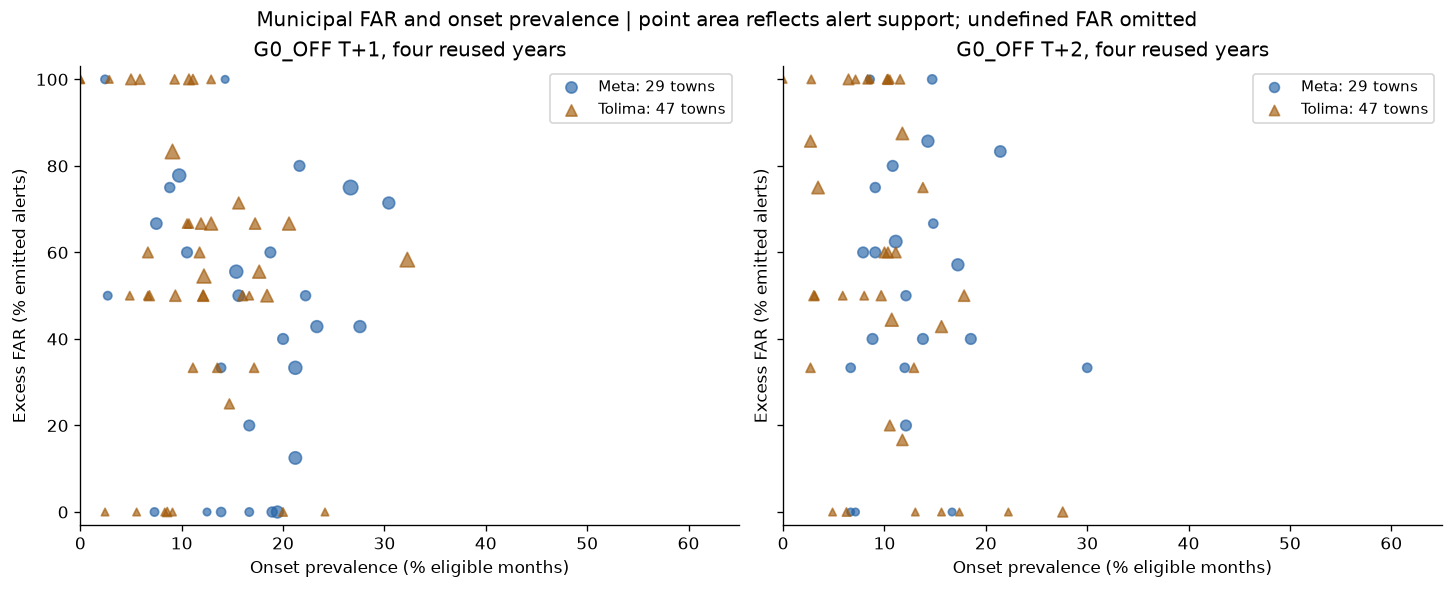

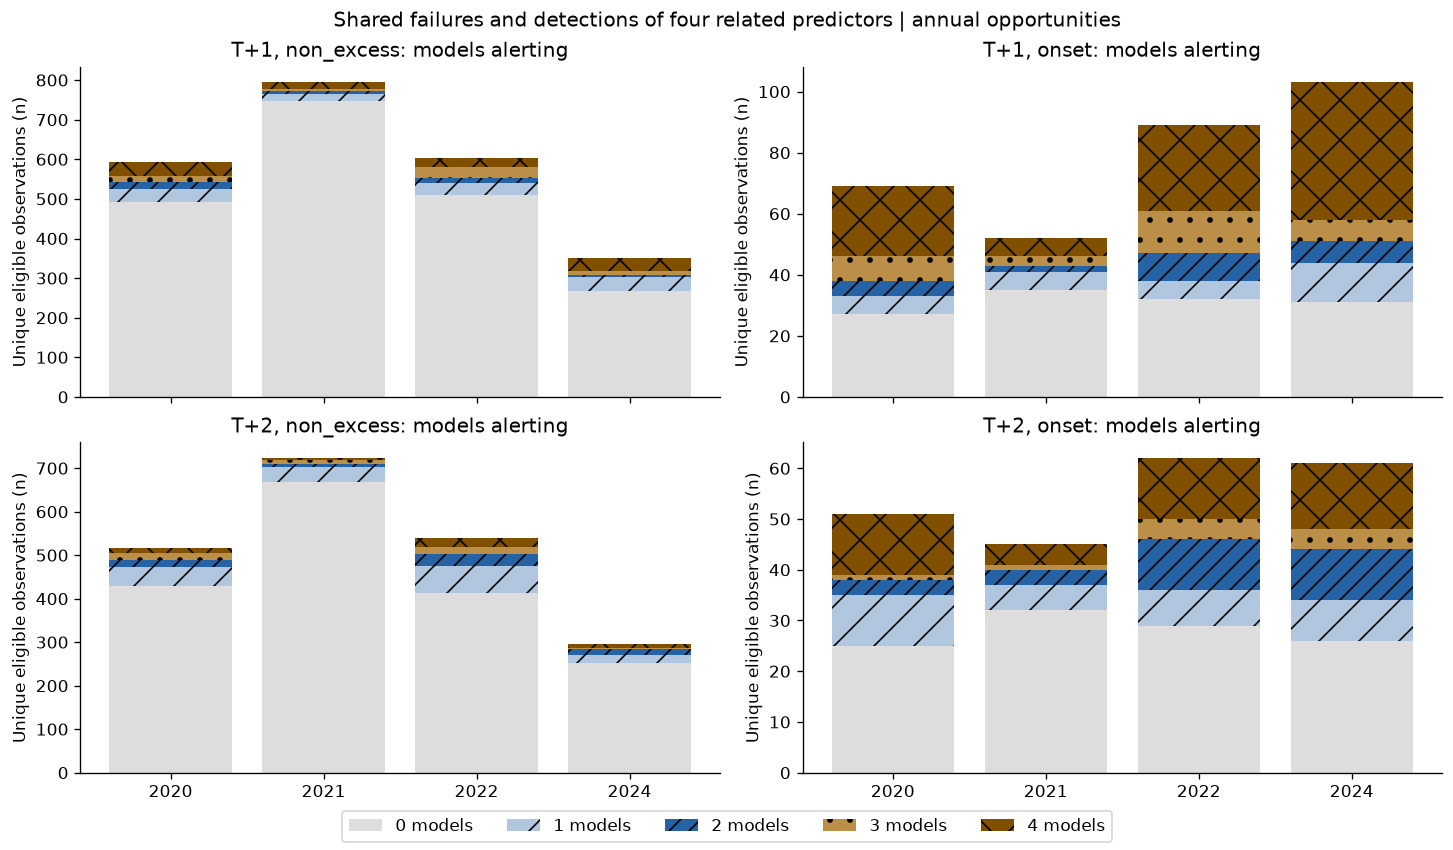

In [11]:
def wilson(k, n):
    if n == 0:
        return np.nan, np.nan
    z = 1.959963984540054
    center = (k / n + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt((k / n) * (1 - k / n) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0, center - half), min(1, center + half)


municipal = group_table(d, ["horizon", "arm", "municipality_code", "department_code"])
municipal_year = group_table(d, ["horizon", "year", "arm", "municipality_code", "department_code"])
for frame in [municipal, municipal_year]:
    for metric, numerator, denominator in [
        ("sensitivity", "detected", "onsets"),
        ("far", "false_excess", "alerts"),
    ]:
        bounds = [
            wilson(int(k), int(n))
            for k, n in zip(frame[numerator], frame[denominator], strict=True)
        ]
        frame[[metric + "_lo", metric + "_hi"]] = bounds
        frame[metric + "_width"] = frame[metric + "_hi"] - frame[metric + "_lo"]
support = []
for h in [1, 2]:
    pooled = municipal[(municipal.horizon == h) & (municipal.arm == "G0_OFF")]
    yearly = municipal_year[(municipal_year.horizon == h) & (municipal_year.arm == "G0_OFF")]
    ordered = pooled.sort_values("false_excess", ascending=False)
    support.append(
        dict(
            horizon=h,
            municipalities=len(pooled),
            municipality_years=len(yearly),
            pooled_under5_onsets=int(pooled.onsets.lt(5).sum()),
            annual_zero_onsets=int(yearly.onsets.eq(0).sum()),
            annual_under3_onsets=int(yearly.onsets.lt(3).sum()),
            annual_under5_alerts=int(yearly.alerts.lt(5).sum()),
            annual_zero_alerts=int(yearly.alerts.eq(0).sum()),
            median_annual_sensitivity_width=yearly.sensitivity_width.median(),
            median_annual_far_width=yearly.far_width.median(),
            municipalities_with_FP=int(pooled.false_excess.gt(0).sum()),
            top7_FP=int(ordered.head(7).false_excess.sum()),
            total_FP=int(pooled.false_excess.sum()),
            top7_exposure=ordered.head(7).exposure.sum(),
            total_exposure=pooled.exposure.sum(),
            annual_onsets_q25=yearly.onsets.quantile(0.25),
            annual_onsets_median=yearly.onsets.median(),
            annual_onsets_q75=yearly.onsets.quantile(0.75),
        )
    )
support = pd.DataFrame(support)
tables.update(municipal=municipal, municipal_year=municipal_year, support=support)
display(support.T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained", sharex=True, sharey=True)
for h, ax in zip([1, 2], axes, strict=True):
    for dep, label, marker in [("50", "Meta", "o"), ("73", "Tolima", "^")]:
        part = municipal[
            (municipal.horizon == h)
            & (municipal.arm == "G0_OFF")
            & (municipal.department_code == dep)
        ]
        ax.scatter(
            100 * part.onset_prevalence,
            100 * part.far,
            s=15 + part.alerts * 5,
            color=COLORS[label],
            marker=marker,
            alpha=0.65,
            label=f"{label}: {len(part)} towns",
        )
    ax.set(
        title=f"G0_OFF T+{h}, four reused years",
        xlabel="Onset prevalence (% eligible months)",
        ylabel="Excess FAR (% emitted alerts)",
        xlim=(0, 65),
        ylim=(-3, 103),
    )
    ax.legend(fontsize=9)
fig.suptitle(
    "Municipal FAR and onset prevalence | point area reflects alert support; undefined FAR omitted"
)
finish(fig, "05_municipal_rates")

fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained", sharex=True)
for i, h in enumerate([1, 2]):
    for j, outcome in enumerate(["non_excess", "onset"]):
        ax = axes[i, j]
        part = tables["multiplicity"].query("horizon == @h and outcome == @outcome")
        bottom = np.zeros(4)
        palette = ["#dddddd", "#b0c7df", "#2563a6", "#bc8f49", "#805000"]
        for k in range(5):
            counts = (
                part[part.models_alerting.eq(k)].set_index("year").reindex(YEARS).rows.to_numpy()
            )
            ax.bar(
                range(4),
                counts,
                bottom=bottom,
                label=f"{k} models",
                color=palette[k],
                hatch=["", "/", "//", ".", "x"][k],
            )
            bottom += counts
        ax.set(
            xticks=range(4),
            xticklabels=YEARS,
            ylabel="Unique eligible observations (n)",
            title=f"T+{h}, {outcome}: models alerting",
        )
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=5)
fig.suptitle("Shared failures and detections of four related predictors | annual opportunities")
finish(fig, "06_shared_outcomes")

At municipality-year resolution 105/300 T+1 and 129/298 T+2 cells have no onsets; 273/300 and 294/298 have fewer than three. Median Wilson sensitivity and FAR reference widths among defined cells are both 79.35 pp. Pooled four-year scatter points do not establish stable municipal policies; dependence further limits the intervals.

In 2022 all four models miss 32/89 T+1 and 29/62 T+2 onsets. Of 94/127 distinct non-excess observations falsely alerted by any model, 65/65 are shared by at least two. G0_OFF additionally detects 71/33 onsets missed by CHANNEL over all four years, but CHANNEL alone detects 19/17 missed by G0_OFF (T+1/T+2). Neither comparator uniformly contains the other.

## 6. Epidemiological boundary and synthesis

Known cases in T are compared with the **target-month** P75. Near-P75 means
absolute difference ≤1 case; ratios exclude P75=0, which is counted separately.
This is an explanatory descriptor of recorded outcomes, never a proposed filter.
Origin zones are known in T; target-minus-one excess below is consulted solely as
an outcome context, never an input or municipal profile.

EXP02's separate full-month cohort showed 87/912 onset labels changed under H5/H9
in 2024: 40 H5 onsets disappeared and 47 appeared. That is historical label-definition
sensitivity, not proof that any present error is a mislabeled outbreak. Its rates
must not be pooled with the eligible benchmark cohort or used to revise H5 here.

rows  near  equal  p75_zero
horizon group                                       
1       CHANNEL_only_FP    24    10      0         6
        G0_FN             167    84     44        38
        G0_FP             179   140     82        28
        G0_TN_excess     2161   702    383       332
        G0_TP             146    94     46        21
        G0_only_FP        118   107     82        20
        G0_only_TP         71    62     46        11
        both_FP            61    33      0         8
2       CHANNEL_only_FP    76    31      0         8
        G0_FN             157    81     46        30
        G0_FP             130    93     49        32
        G0_TN_excess     1944   677    364       297
        G0_TP              62    41     19        16
        G0_only_FP         92    74     49        24
        G0_only_TP         33    28     19        11
        both_FP            38    19      0         8

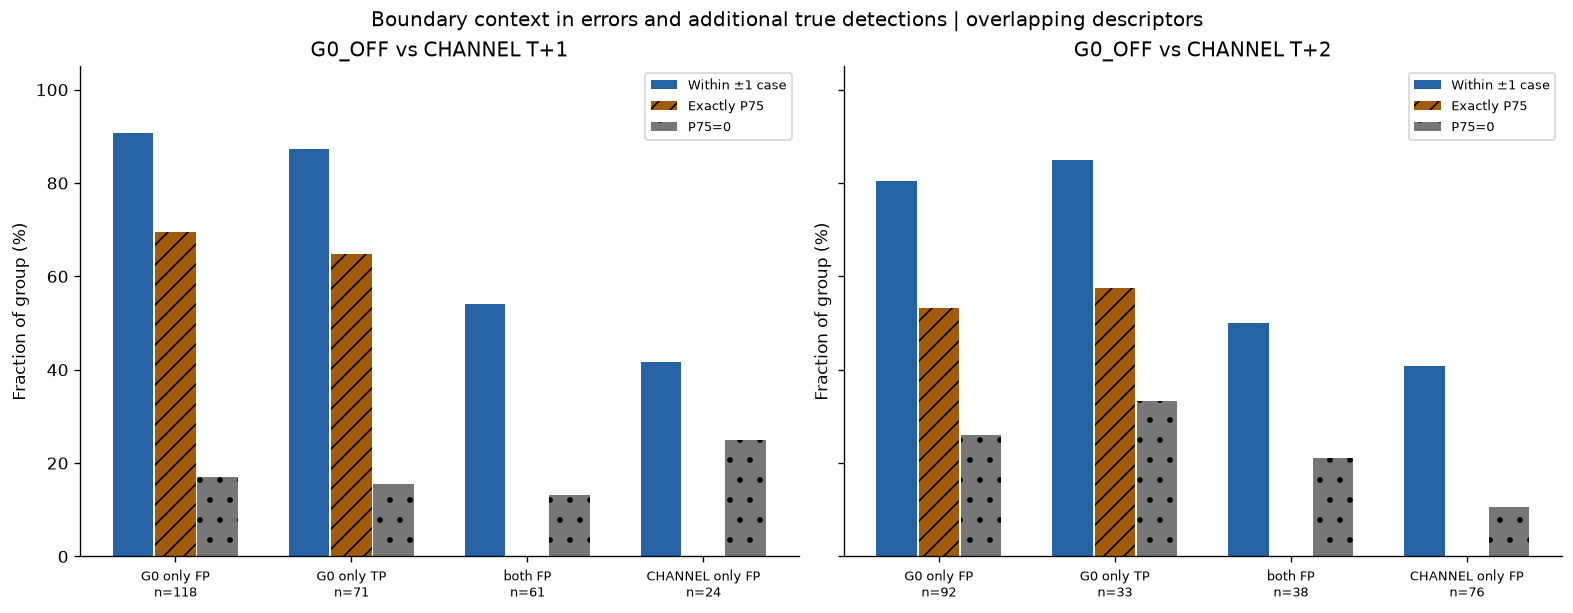

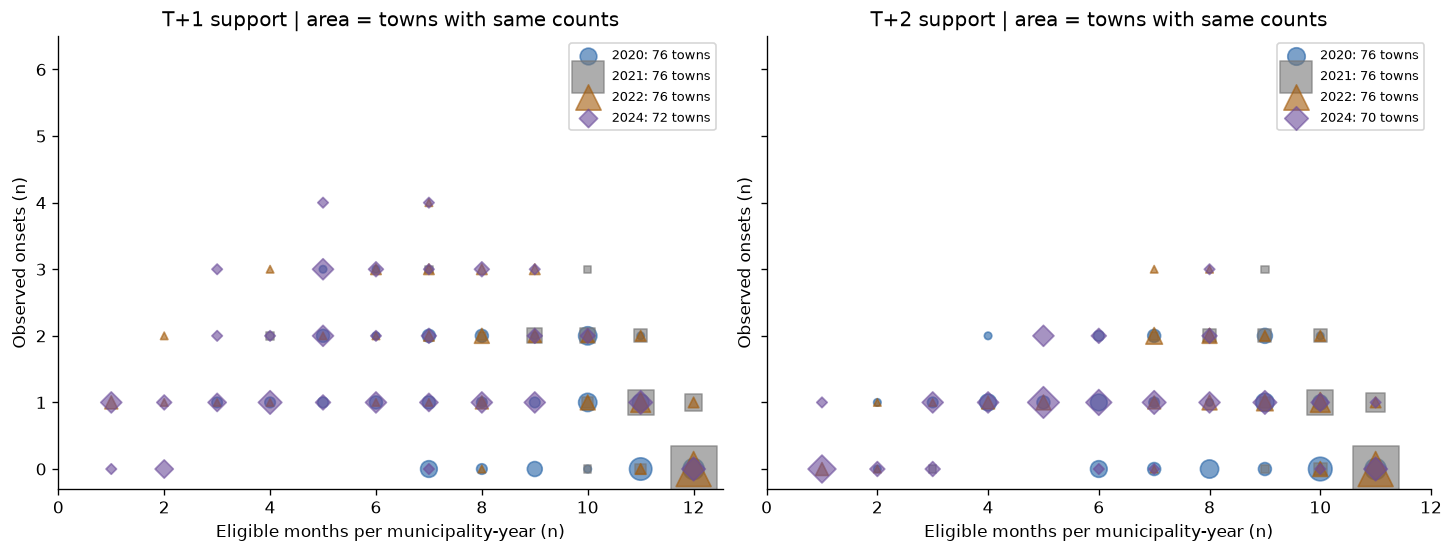

In [12]:
boundary_rows = []
zone_rows = []
for (h, year), part in g0.groupby(["horizon", "year"]):
    channel = d[(d.arm == "CHANNEL") & (d.horizon == h) & (d.year == year)].set_index(KEYS)
    part = part.set_index(KEYS).sort_index()
    channel = channel.reindex(part.index)
    groups = {
        "G0_only_FP": part.alert & ~channel.alert & part.target_excess.eq(0),
        "CHANNEL_only_FP": ~part.alert & channel.alert & part.target_excess.eq(0),
        "both_FP": part.alert & channel.alert & part.target_excess.eq(0),
        "G0_only_TP": part.alert & ~channel.alert & part.truth.eq(1),
        "G0_FP": part.alert & part.target_excess.eq(0),
        "G0_TP": part.alert & part.truth.eq(1),
        "G0_FN": ~part.alert & part.truth.eq(1),
        "G0_TN_excess": ~part.alert & part.target_excess.eq(0),
    }
    for group, mask in groups.items():
        sub = part[mask]
        near = (sub.origin_count - sub.target_p75).abs().le(1)
        valid_ratio = sub.origin_count.div(sub.target_p75.where(sub.target_p75.gt(0)))
        boundary_rows.append(
            dict(
                horizon=h,
                year=year,
                group=group,
                rows=len(sub),
                near=int(near.sum()),
                equal=int(sub.origin_count.eq(sub.target_p75).sum()),
                p75_zero=int(sub.target_p75.eq(0).sum()),
                cases_median=sub.origin_count.median(),
                p75_median=sub.target_p75.median(),
                ratio_median=valid_ratio.median(),
                ratio_n=int(valid_ratio.notna().sum()),
                margin_median=(sub.score - sub.threshold).median(),
            )
        )
        for zone, block in sub.groupby("origin_zone"):
            zone_rows.append(
                dict(horizon=h, year=year, group=group, origin_zone=zone, rows=len(block))
            )
boundary = pd.DataFrame(boundary_rows)
tables.update(boundary=boundary, origin_zones=pd.DataFrame(zone_rows))
for row in diagnostic["P1_groups"]:
    observed = boundary[(boundary.horizon == 1) & (boundary.group == row["group"])][
        ["rows", "near", "equal", "p75_zero"]
    ].sum()
    for ours, theirs in [
        ("rows", "rows"),
        ("near", "near_p75_one_case"),
        ("equal", "equal_p75"),
        ("p75_zero", "p75_zero"),
    ]:
        assert observed[ours] == row[theirs]
display(boundary.groupby(["horizon", "group"])[["rows", "near", "equal", "p75_zero"]].sum())

# The canonical table is needed only to resolve the prior state, not to rebuild labels.
canonical_spec = json.loads((ROOT / BENCH / "protocol.json").read_text())["sources"]["canonical"]
cm = verify_publication(canonical_spec["path"], canonical_spec["manifest_sha256"])
canonical = read_csv(canonical_spec["path"] + "/canonical_model_table_v1.csv")
states = canonical.set_index(["municipality_code", "year_month"]).zona_canal_t
prior = []
for row in g0.itertuples(index=False):
    previous = str(pd.Period(row.target_month, freq="M") - 1)
    zone = states.loc[(row.municipality_code, previous)]
    assert pd.notna(zone)
    prior.append(zone)
g0["prior_target_zone"] = prior
tables["prior_states"] = group_table(g0, ["horizon", "year", "prior_target_zone"])
assert (
    g0.loc[g0.horizon.eq(1), "prior_target_zone"].eq(g0.loc[g0.horizon.eq(1), "origin_zone"]).all()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained", sharey=True)
for h, ax in zip([1, 2], axes, strict=True):
    agg = (
        boundary[boundary.horizon.eq(h)]
        .groupby("group")[["rows", "near", "equal", "p75_zero"]]
        .sum()
    )
    groups = ["G0_only_FP", "G0_only_TP", "both_FP", "CHANNEL_only_FP"]
    for i, (metric, color, hatch) in enumerate(
        [("near", "#2563a6", ""), ("equal", "#a25b0b", "//"), ("p75_zero", "#777777", ".")]
    ):
        values = [100 * ratio(agg.loc[group, metric], agg.loc[group, "rows"]) for group in groups]
        ax.bar(
            np.arange(4) + i * 0.24,
            values,
            width=0.23,
            color=color,
            hatch=hatch,
            label={"near": "Within ±1 case", "equal": "Exactly P75", "p75_zero": "P75=0"}[metric],
        )
    labels = [f"{group.replace('_', ' ')}\nn={agg.loc[group, 'rows']}" for group in groups]
    ax.set(
        xticks=np.arange(4) + 0.24,
        xticklabels=labels,
        ylabel="Fraction of group (%)",
        ylim=(0, 105),
        title=f"G0_OFF vs CHANNEL T+{h}",
    )
    ax.tick_params(axis="x", labelsize=8)
    ax.legend(fontsize=8)
fig.suptitle("Boundary context in errors and additional true detections | overlapping descriptors")
finish(fig, "07_p75_boundary")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained", sharey=True)
for h, ax in zip([1, 2], axes, strict=True):
    part = municipal_year[(municipal_year.horizon == h) & (municipal_year.arm == "G0_OFF")]
    for year, marker, color in zip(
        YEARS, ["o", "s", "^", "D"], ["#2563a6", "#777777", "#a25b0b", "#6b4c9a"], strict=True
    ):
        sub = part[part.year.eq(year)]
        # Aggregate identical integer pairs; bubble area = number of municipalities.
        counts = sub.groupby(["rows", "onsets"]).size().reset_index(name="towns")
        ax.scatter(
            counts.rows,
            counts.onsets,
            s=counts.towns * 20,
            marker=marker,
            color=color,
            alpha=0.6,
            label=f"{year}: {len(sub)} towns",
        )
    ax.set(
        xlabel="Eligible months per municipality-year (n)",
        ylabel="Observed onsets (n)",
        title=f"T+{h} support | area = towns with same counts",
        xticks=range(0, 13, 2),
        ylim=(-0.3, 6.5),
    )
    ax.legend(fontsize=8)
finish(fig, "08_municipal_support")

For T+1, 107/118 G0-only false alerts and 62/71 G0-only true detections lie within one case of target P75; equality occurs in 82/118 and 46/71. At T+2, the corresponding near-boundary fractions are 74/92 and 28/33. Small-P75 ambiguity is shared by failures and successes, so it does not validate a filtering rule.

Municipal event counts range from zero to four per observed year. The top seven municipalities by observed false alerts account for 51/179 (T+1) and 40/130 (T+2), over 20.08/221.08 and 19.17/201.83 eligible municipality-years. This is retrospective concentration with unequal exposure, not a future risk classification.

### Traceable synthesis and private derived publication

Interpretation is owned by `docs/product/experiments/EDA-EXP01/FINDINGS.md` and
`CONCLUSIONS.md`. The new evidence decomposes territorial rates and measures municipal
support; historical benchmark/DELTA findings are corroborated, not independent evidence.
No single causal bottleneck can be identified. Ranking and calibration vary by
year/horizon; policy feasibility and transport both fail in observed cells.
Validated transmission profiles are unavailable. Small-P75 context occurs in both
errors and additional detections, so it cannot justify an alert filter.

Prioritize the hypothesis that **weak local onset separation and changing composition
jointly limit the transport of the academic alert margin**. A later study would need
a predeclared independent period and stable, historically defined strata before any
intervention. This EDA does not authorize or automatically name EXP-DELTA02.

In [13]:
# Publish only derived tables, no historical prediction copies or models.
# Verify every source again after calculations. Identical reruns reuse only equal bytes.
for rel, expected in sources.items():
    assert identity(ROOT / rel) == expected, rel
nb = json.loads((ROOT / "notebooks/eda_experimental_results.ipynb").read_text())
source_cells = [{"cell_type": c["cell_type"], "source": "".join(c["source"])} for c in nb["cells"]]
environment = {
    name: importlib.metadata.version(name)
    for name in ["numpy", "pandas", "scikit-learn", "matplotlib", "nbformat", "nbclient"]
}
settings = dict(
    schema="eda-exp01-v1",
    near_p75_cases=1,
    probability_bins=list(np.linspace(0, 1, 11)),
    reliability_min_rows=30,
    reliability_min_per_class=5,
    uncertainty="95% Wilson binomial reference; dependence not accounted for; descriptive only",
    G5="NOT_APPROVED",
    champion="not_selected",
    inference_calls=0,
    model_fits=0,
    calibrations=0,
    threshold_searches=0,
    transmission_profiles="BLOCKED_NO_VALIDATED_CLASSIFICATION",
)
payloads = {name + ".csv": serialize_table(frame) for name, frame in sorted(tables.items())}
payloads["settings.json"] = canonical_bytes(settings)
manifest = dict(
    schema="eda-exp01-publication-v1",
    sources=sources,
    environment=environment,
    notebook_source_sha256=hashlib.sha256(canonical_bytes(source_cells)).hexdigest(),
    files={name: bytes_record(payload) for name, payload in sorted(payloads.items())},
    validation=dict(
        benchmark_strata=180,
        delta_strata=60,
        paired_keys=5075,
        complete_cohorts=True,
        historical_sources_unchanged=True,
    ),
    **{"G5": "NOT_APPROVED", "champion": "not_selected"},
)
bundle_id = hashlib.sha256(canonical_bytes(manifest)).hexdigest()
manifest["bundle_id"] = bundle_id
payloads["manifest.json"] = canonical_bytes(manifest)
publication = publish_bundle(ROOT / "data/processed/eda_exp01", bundle_id, payloads)
print("Private derived publication:", publication.relative_to(ROOT))
print("Manifest SHA-256:", bytes_record(payloads["manifest.json"])["sha256"])
print("Historical source files verified before/after:", len(sources))
print("Tables:", len(tables), "| figures: 8 | inference/fits/calibration/threshold searches: 0")

Private derived publication: data/processed/eda_exp01/3d0803788eab1bbc92f29410540b184ff11b07ab921b611b5fd5965ed05e356e
Manifest SHA-256: 6c3ff1a8a2c5a97b7306a28b30f0f8f305dbdbb87209025be8b16150dbbc8002
Historical source files verified before/after: 506
Tables: 21 | figures: 8 | inference/fits/calibration/threshold searches: 0
